# Image Denoising with a Convolutional Denoising Autoencoder (DAE)
**Framework:** TensorFlow / Keras  |  **Dataset:** Fashion-MNIST (70,000 grayscale images, 28x28, 10 clothing classes)

**Main idea:** We give the model a *noisy* image and ask it to rebuild the *clean* image.
After training, the model can remove noise from images it has never seen.

## 1. Install / import libraries and load the dataset
Fashion-MNIST is built into Keras, so `keras.datasets` downloads it automatically.

> **Kaggle note:** if your notebook has *Internet OFF*, the download fails. In that case, add the Kaggle dataset
> **"Fashion MNIST" by Zalando Research** (https://www.kaggle.com/datasets/zalando-research/fashionmnist) with *+ Add Input*.
> The code below then reads the CSV files automatically.

In [1]:
import os                                    # to work with file paths (needed for the Kaggle CSV fallback)
import numpy as np                           # NumPy: arrays and math operations
import pandas as pd                          # Pandas: tables (used to read CSV and show results)
import matplotlib.pyplot as plt              # Matplotlib: to draw images and plots
import tensorflow as tf                      # TensorFlow: the deep learning library
from tensorflow import keras                 # Keras: the high-level API to build models
from tensorflow.keras import layers          # layers: Conv2D, MaxPooling2D, etc.

np.random.seed(42)                           # fix NumPy randomness so the noise is reproducible
tf.random.set_seed(42)                       # fix TensorFlow randomness (weight initialization)

print("TensorFlow version:", tf.__version__) # show the installed TensorFlow version

TensorFlow version: 2.21.0


In [2]:
def load_fashion_mnist():                                    # function that returns train and test data
    """Try Keras download first; if there is no internet (Kaggle), read the CSV files."""
    try:                                                     # first try: download with Keras
        (x_tr, y_tr), (x_te, y_te) = keras.datasets.fashion_mnist.load_data()  # returns images + labels
        print("Loaded from keras.datasets")                  # tell the user which method worked
    except Exception as e:                                   # if the download fails (no internet)
        print("Keras download failed, using Kaggle CSV files instead.")  # inform the user
        base = "/kaggle/input/fashionmnist"                  # folder of the dataset added to the Kaggle notebook
        train = pd.read_csv(os.path.join(base, "fashion-mnist_train.csv"))  # read the training CSV
        test  = pd.read_csv(os.path.join(base, "fashion-mnist_test.csv"))   # read the test CSV
        y_tr = train.iloc[:, 0].values                       # first column = labels (train)
        x_tr = train.iloc[:, 1:].values.reshape(-1, 28, 28).astype("uint8")  # other 784 columns -> 28x28 images
        y_te = test.iloc[:, 0].values                        # first column = labels (test)
        x_te = test.iloc[:, 1:].values.reshape(-1, 28, 28).astype("uint8")   # 784 pixels -> 28x28 images
    return (x_tr, y_tr), (x_te, y_te)                        # give back the data

(x_train_raw, _), (x_test_raw, _) = load_fashion_mnist()     # call the function; "_" ignores labels (not needed here)

print("Train images:", x_train_raw.shape)                    # expected: (60000, 28, 28)
print("Test images :", x_test_raw.shape)                     # expected: (10000, 28, 28)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loaded from keras.datasets
Train images: (60000, 28, 28)
Test images : (10000, 28, 28)


## 2. Preprocess the data
- **Normalization:** pixels go from 0-255 to 0-1 (helps the network train faster and matches the sigmoid output).
- **Reshaping:** Conv2D layers expect `(height, width, channels)`, so we add a channel dimension (1 = grayscale).
- **Train / validation / test split:** the dataset already has 60,000 train + 10,000 test images.
  We take 10% of the train set as validation data to watch overfitting.

In [3]:
x_train_full = x_train_raw.astype("float32") / 255.0   # convert to float and scale pixels from 0-255 to 0-1
x_test       = x_test_raw.astype("float32") / 255.0    # same normalization for the test images

x_train_full = np.expand_dims(x_train_full, -1)        # add channel axis: (N, 28, 28) -> (N, 28, 28, 1)
x_test       = np.expand_dims(x_test, -1)              # same reshaping for the test images

val_size = int(0.1 * len(x_train_full))                # 10% of the training set = number of validation images
x_val   = x_train_full[:val_size]                      # first 10% of images -> validation set
x_train = x_train_full[val_size:]                      # remaining 90% -> training set

print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)  # check the shapes

Train: (54000, 28, 28, 1) | Validation: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)


## 3. Add artificial noise
We add **Gaussian noise** (random values from a normal distribution) to every pixel.
`NOISE_FACTOR` controls the strength: bigger value = more noise. **You can change it.**
After adding noise, some pixels go below 0 or above 1, so we **clip** them back to [0, 1].

In [4]:
NOISE_FACTOR = 0.4   # <-- change this value to make images more / less noisy

def add_noise(images, noise_factor):                                   # function that adds Gaussian noise
    """Return a noisy copy of the images, clipped to [0, 1]."""
    noise = noise_factor * np.random.normal(loc=0.0, scale=1.0, size=images.shape)  # random values (mean 0, std 1) x strength
    noisy = images + noise                                             # add the noise to the clean pixels
    return np.clip(noisy, 0.0, 1.0).astype("float32")                  # force values back into [0, 1]

x_train_noisy = add_noise(x_train, NOISE_FACTOR)   # noisy version of the training images
x_val_noisy   = add_noise(x_val,   NOISE_FACTOR)   # noisy version of the validation images
x_test_noisy  = add_noise(x_test,  NOISE_FACTOR)   # noisy version of the test images

## 4. Visualize clean vs. noisy samples
Top row = clean images, bottom row = the same images with noise.

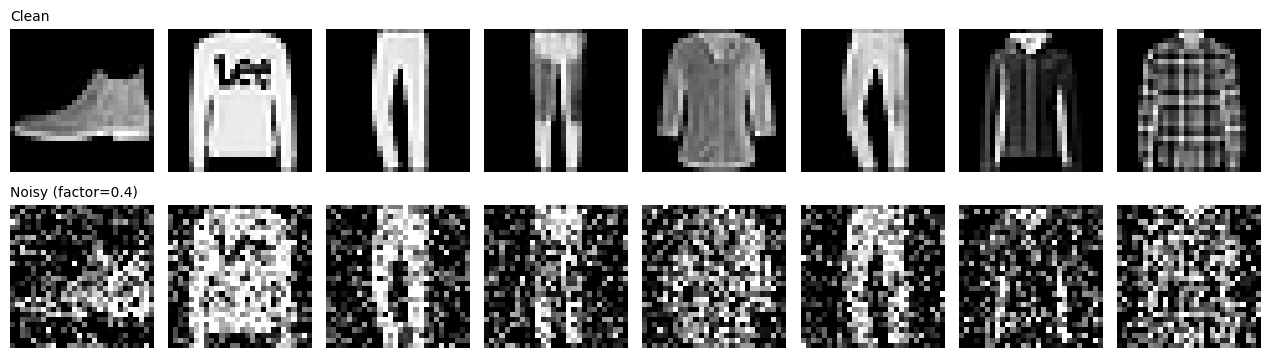

In [5]:
def show_images(rows, titles, n=8):                                   # function to display rows of images
    """Display n images per row. rows = list of image arrays, titles = row names."""
    plt.figure(figsize=(n * 1.6, len(rows) * 1.9))                    # set the size of the whole figure
    for r, (imgs, title) in enumerate(zip(rows, titles)):             # loop over each row (clean, noisy, ...)
        for i in range(n):                                            # loop over the n images of this row
            ax = plt.subplot(len(rows), n, r * n + i + 1)             # create the cell for this image in the grid
            plt.imshow(imgs[i].squeeze(), cmap="gray", vmin=0, vmax=1)  # draw it in grayscale (squeeze removes channel axis)
            ax.axis("off")                                            # hide the axes
            if i == 0:                                                # only for the first image of the row
                ax.set_title(title, fontsize=10, loc="left")          # write the row name
    plt.tight_layout()                                                # avoid overlapping
    plt.show()                                                        # display the figure

show_images([x_test, x_test_noisy], ["Clean", f"Noisy (factor={NOISE_FACTOR})"])  # clean row on top, noisy row below

## 5. Build the convolutional autoencoder
Three parts:
- **Encoder:** Conv + MaxPooling layers shrink the image and keep the important features.
- **Bottleneck:** the smallest layer (7x7x8 = 392 values vs. 784 pixels). It forces the model to keep only useful information, not the noise.
- **Decoder:** Conv + UpSampling layers rebuild the image back to 28x28.

The last layer uses **sigmoid** so outputs stay in [0, 1], like our pixels.

In [6]:
def build_dae():                                                                  # function that builds the model
    inputs = keras.Input(shape=(28, 28, 1), name="noisy_image")                   # input: 28x28 grayscale image

    # ---------- Encoder ----------
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)     # 32 filters 3x3 -> 28x28x32
    x = layers.MaxPooling2D((2, 2), padding="same")(x)                            # keep max of each 2x2 block -> 14x14x32
    x = layers.Conv2D(16, (3, 3), activation="relu", padding="same")(x)           # 16 filters -> 14x14x16
    x = layers.MaxPooling2D((2, 2), padding="same")(x)                            # halve size again -> 7x7x16

    # ---------- Bottleneck ----------
    bottleneck = layers.Conv2D(8, (3, 3), activation="relu", padding="same", name="bottleneck")(x)  # smallest layer: 7x7x8 = 392 values

    # ---------- Decoder ----------
    x = layers.Conv2D(16, (3, 3), activation="relu", padding="same")(bottleneck)  # start rebuilding -> 7x7x16
    x = layers.UpSampling2D((2, 2))(x)                                            # double the size -> 14x14x16
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)           # 32 filters -> 14x14x32
    x = layers.UpSampling2D((2, 2))(x)                                            # double again -> 28x28x32

    outputs = layers.Conv2D(1, (3, 3), activation="sigmoid", padding="same", name="denoised_image")(x)  # 1 channel, sigmoid keeps values in [0,1]

    return keras.Model(inputs, outputs, name="denoising_autoencoder")             # build the model from input to output

autoencoder = build_dae()                                  # create the model

autoencoder.compile(optimizer="adam", loss="mse")          # Adam updates weights; MSE compares output vs clean image
autoencoder.summary()                                      # print layers, output shapes and number of parameters

Model: "denoising_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noisy_image (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Conv2D)             │ (None, 7, 7, 8)        │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 16)       │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ denoised_image (Conv2D)         │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,201 (47.66 KB)

 Trainable params: 12,201 (47.66 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model
**Input = noisy images, Target = clean images.** This is what makes it a *denoising* autoencoder.
We pass validation data to check that the model also works on images it does not train on.

In [7]:
EPOCHS = 20          # number of full passes over the training data
BATCH_SIZE = 128     # number of images processed before each weight update

history = autoencoder.fit(                        # start training; "history" stores the losses
    x_train_noisy, x_train,                       # input = noisy images, target = clean images
    epochs=EPOCHS,                                # how many epochs to train
    batch_size=BATCH_SIZE,                        # mini-batch size
    shuffle=True,                                 # mix the images at each epoch
    validation_data=(x_val_noisy, x_val),         # validation: noisy input, clean target (not used for learning)
    verbose=1,                                    # show the progress bar
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - loss: 0.0356 - val_loss: 0.0207
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0194 - val_loss: 0.0182
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0175 - val_loss: 0.0170
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0166 - val_loss: 0.0164
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0161 - val_loss: 0.0160
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0157 - val_loss: 0.0155
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0153 - val_loss: 0.0152
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0151 - val_loss: 0.0150
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0148 - val_loss: 0.0148
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0146 - val_loss: 0.0146
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0144 - val_loss: 0.0144
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/st

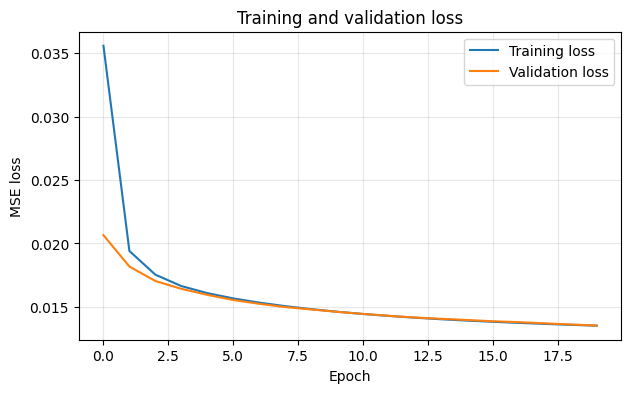

In [8]:
plt.figure(figsize=(7, 4))                                      # create a figure of size 7x4
plt.plot(history.history["loss"], label="Training loss")        # curve of the training loss per epoch
plt.plot(history.history["val_loss"], label="Validation loss")  # curve of the validation loss per epoch
plt.xlabel("Epoch"); plt.ylabel("MSE loss")                     # axis names
plt.title("Training and validation loss")                       # plot title
plt.legend(); plt.grid(alpha=0.3)                               # show legend and a light grid
plt.show()                                                      # display the plot

## 7. Evaluate on the test set
We compare images with 3 metrics:
- **MSE** (Mean Squared Error): average squared pixel difference. *Lower is better.*
- **PSNR** (Peak Signal-to-Noise Ratio, in dB): image quality. *Higher is better.*
- **SSIM** (Structural Similarity): how similar the structures are, from 0 to 1. *Higher is better.*

We also compute them for the **noisy** images, as a baseline: the denoised result should be better than the noisy one.

In [9]:
def evaluate_metrics(clean, other):                                           # compare clean images with another set
    """MSE, PSNR and SSIM between clean images and another set of images (values in [0,1])."""
    mse  = float(np.mean((clean - other) ** 2))                               # average squared pixel difference
    psnr = float(tf.reduce_mean(tf.image.psnr(clean, other, max_val=1.0)))    # mean PSNR in dB (max pixel value = 1)
    ssim = float(tf.reduce_mean(tf.image.ssim(clean, other, max_val=1.0)))    # mean structural similarity
    return mse, psnr, ssim                                                    # give back the 3 metrics

x_test_denoised = autoencoder.predict(x_test_noisy, verbose=0)                # run the model on the noisy test images

results = pd.DataFrame(                                                       # build a small results table
    {                                                                         # dictionary: column name -> metrics
        "Noisy vs Clean":    evaluate_metrics(x_test, x_test_noisy),          # baseline: how bad is the noisy image
        "Denoised vs Clean": evaluate_metrics(x_test, x_test_denoised),       # how good is the denoised image
    },
    index=["MSE (lower=better)", "PSNR dB (higher=better)", "SSIM (higher=better)"],  # row names
).round(4)                                                                    # round to 4 decimals
results                                                                       # display the table

,Noisy vs Clean,Denoised vs Clean
MSE (lower=better),0.0849,0.0136
PSNR dB (higher=better),10.7254,19.0722
SSIM (higher=better),0.3218,0.6372


## 8. Final comparison: original vs. noisy vs. denoised

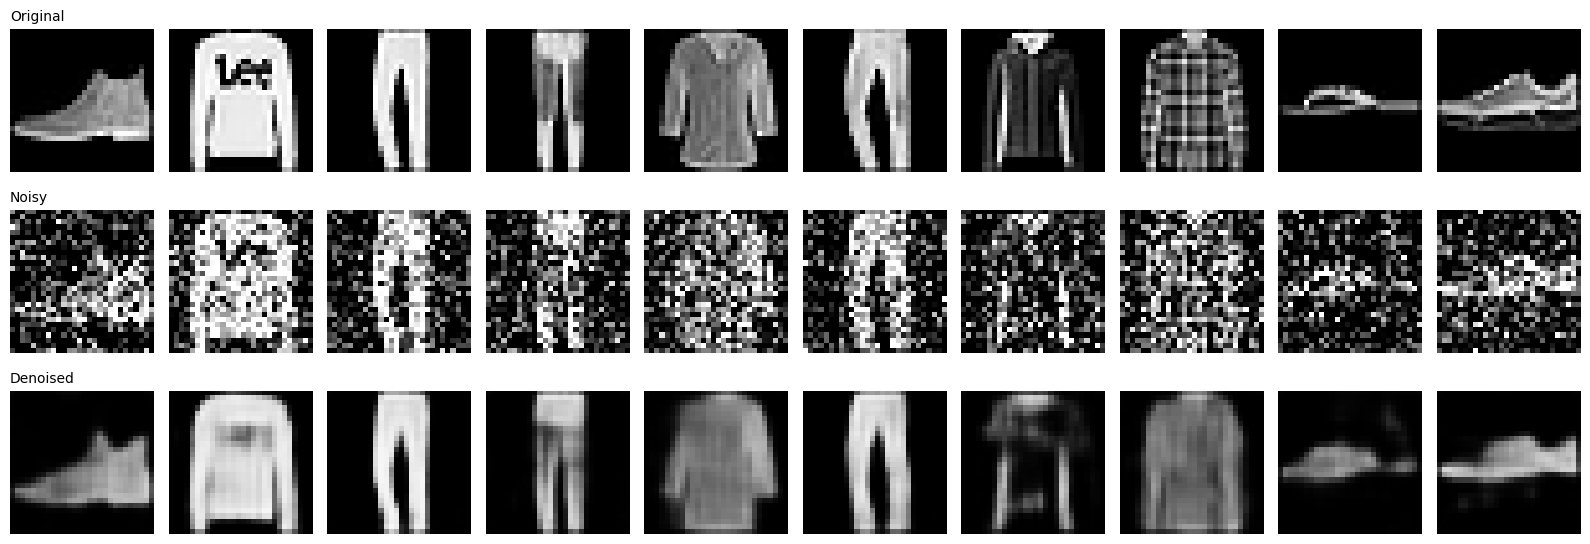

In [10]:
show_images(                                           # reuse our display function
    [x_test, x_test_noisy, x_test_denoised],           # 3 rows: original, noisy, denoised
    ["Original", "Noisy", "Denoised"],                 # names of the rows
    n=10,                                              # show 10 images per row
)

## 9. Test with a different noise level
The model was trained with `NOISE_FACTOR = 0.4`. What happens with **less** and **more** noise?
(We do not retrain, we only change the test noise.)

,Noise factor,PSNR noisy,PSNR denoised,SSIM noisy,SSIM denoised,MSE denoised
0,0.1,21.6234,19.8303,0.7202,0.6882,0.0116
1,0.3,12.8083,19.7341,0.4118,0.6775,0.0118
2,0.5,9.2977,17.7861,0.2576,0.5639,0.0179
3,0.7,7.5813,14.8481,0.1785,0.4145,0.0341


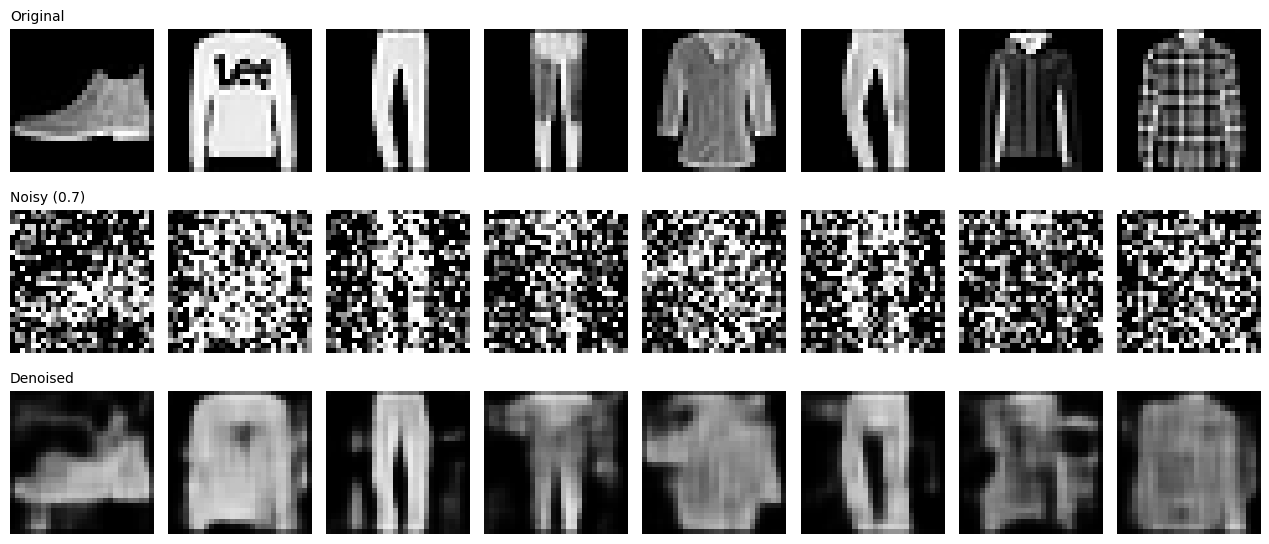

In [11]:
test_levels = [0.1, 0.3, 0.5, 0.7]                                   # new noise levels to test (model trained on 0.4)
rows = []                                                            # list that will store the results
for nf in test_levels:                                               # loop over each noise level
    noisy = add_noise(x_test, nf)                                    # add noise with this level
    denoised = autoencoder.predict(noisy, verbose=0)                 # denoise with the trained model (no retraining)
    _, psnr_n, ssim_n = evaluate_metrics(x_test, noisy)              # metrics of the noisy images (MSE ignored with "_")
    mse_d, psnr_d, ssim_d = evaluate_metrics(x_test, denoised)       # metrics of the denoised images
    rows.append([nf, psnr_n, psnr_d, ssim_n, ssim_d, mse_d])         # save one line of results

df_levels = pd.DataFrame(                                            # make a table from the results
    rows,                                                            # the data collected in the loop
    columns=["Noise factor", "PSNR noisy", "PSNR denoised", "SSIM noisy", "SSIM denoised", "MSE denoised"],  # column names
).round(4)                                                           # round to 4 decimals
display(df_levels)                                                   # show the table

nf = test_levels[-1]                                                 # take the highest noise level (0.7)
noisy_hi = add_noise(x_test, nf)                                     # create very noisy test images
show_images([x_test, noisy_hi, autoencoder.predict(noisy_hi, verbose=0)],  # original / noisy / denoised
            ["Original", f"Noisy ({nf})", "Denoised"], n=8)          # row names, 8 images each